In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


# Load Dataset

In [4]:
data=pd.read_csv('loan_approval_data.csv')
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Applicant_ID        950 non-null    float64
 1   Applicant_Income    950 non-null    float64
 2   Coapplicant_Income  950 non-null    float64
 3   Employment_Status   950 non-null    str    
 4   Age                 950 non-null    float64
 5   Marital_Status      950 non-null    str    
 6   Dependents          950 non-null    float64
 7   Credit_Score        950 non-null    float64
 8   Existing_Loans      950 non-null    float64
 9   DTI_Ratio           950 non-null    float64
 10  Savings             950 non-null    float64
 11  Collateral_Value    950 non-null    float64
 12  Loan_Amount         950 non-null    float64
 13  Loan_Term           950 non-null    float64
 14  Loan_Purpose        950 non-null    str    
 15  Property_Area       950 non-null    str    
 16  Education_Level   

In [5]:
# Identify numerical and categorical columns
categorical_cols = data.select_dtypes(include="object").columns
numerical_cols = data.select_dtypes(include=["float64", "int64"]).columns

# Handle missing numerical values using the mean
num_imp = SimpleImputer(strategy="mean")
data[numerical_cols] = num_imp.fit_transform(data[numerical_cols])

# Handle missing categorical values using the most frequent value
cat_imp = SimpleImputer(strategy="most_frequent")
data[categorical_cols] = cat_imp.fit_transform(data[categorical_cols])

C:\Users\rajpa\AppData\Local\Temp\ipykernel_22592\1206375166.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = data.select_dtypes(include="object").columns


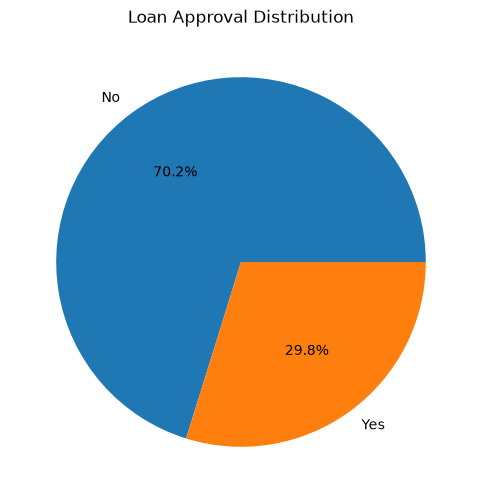

In [6]:
# Visualize loan approval distribution
classes_count = data["Loan_Approved"].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(
    classes_count,
    labels=classes_count.index,
    autopct="%1.1f%%"
)
plt.title("Loan Approval Distribution")
plt.show()

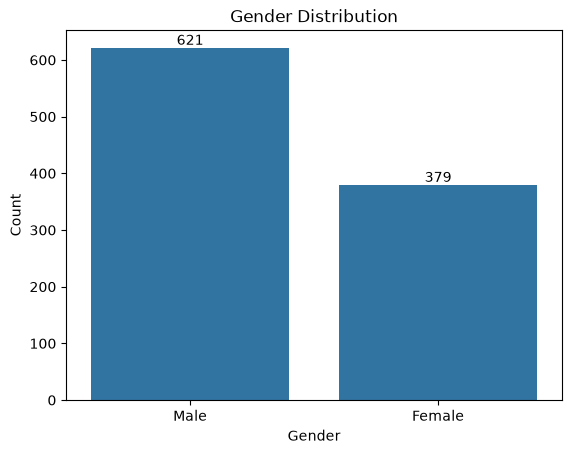

In [7]:
# Visualize gender distribution
gender_count = data["Gender"].value_counts()

ax = sns.barplot(x=gender_count.index, y=gender_count.values)
ax.bar_label(ax.containers[0])

plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Count")
plt.show()

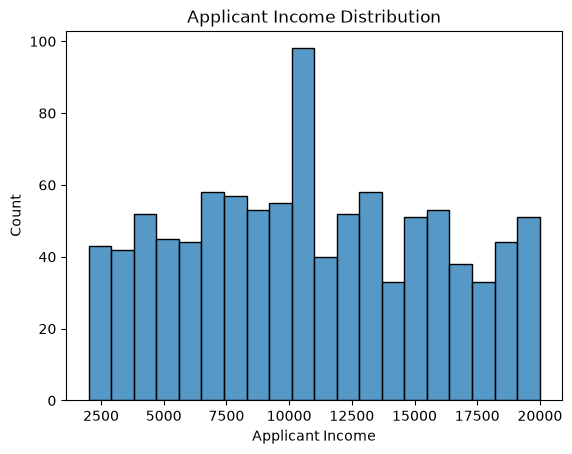

In [8]:
# Analyze applicant income distribution

sns.histplot(
    data=data,
    x="Applicant_Income",
    bins=20
)

plt.title("Applicant Income Distribution")
plt.xlabel("Applicant Income")
plt.ylabel("Count")
plt.show()

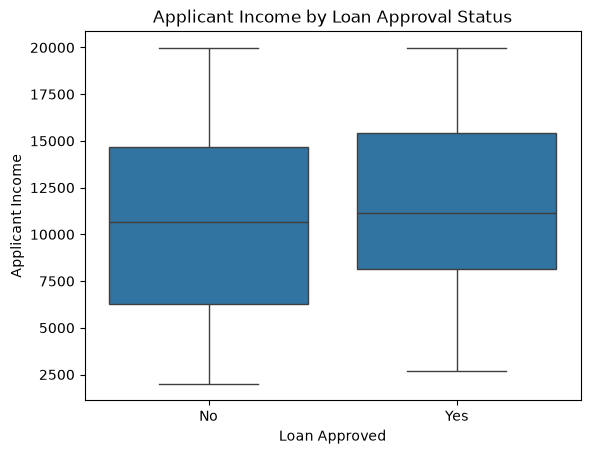

In [9]:
# Detect outliers using a box plot

sns.boxplot(
    data=data,
    x="Loan_Approved",
    y="Applicant_Income"
)

plt.title("Applicant Income by Loan Approval Status")
plt.xlabel("Loan Approved")
plt.ylabel("Applicant Income")
plt.show()

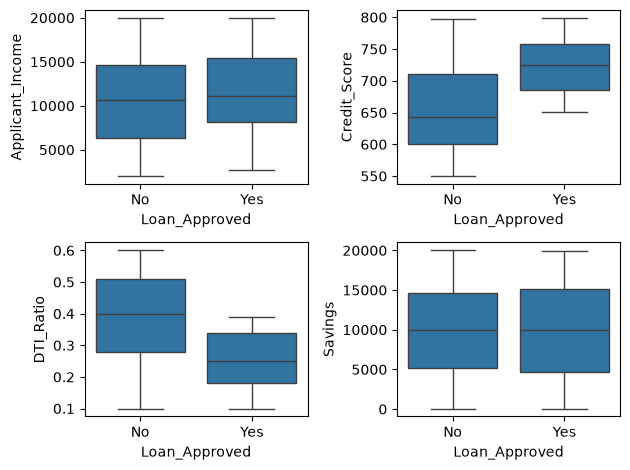

In [10]:
fig,axes=plt.subplots(2,2)

sns.boxplot(
    ax=axes[0, 0],
    data=data,
    x="Loan_Approved",
    y="Applicant_Income"
)

sns.boxplot(
    ax=axes[0, 1],
    data=data,
    x="Loan_Approved",
    y="Credit_Score"
)

sns.boxplot(
    ax=axes[1, 0],
    data=data,
    x="Loan_Approved",
    y="DTI_Ratio"
)

sns.boxplot(
    ax=axes[1, 1],
    data=data,
    x="Loan_Approved",
    y="Savings"
)

plt.tight_layout()
plt.show()


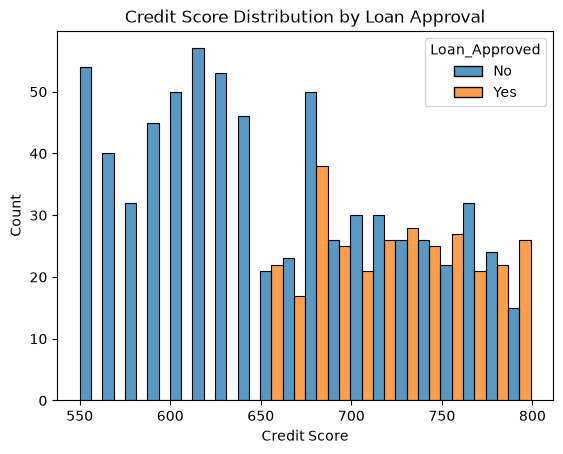

In [11]:
sns.histplot(
    data=data,
    x="Credit_Score",
    hue="Loan_Approved",
    multiple="dodge",
    bins=20
)

plt.title("Credit Score Distribution by Loan Approval")
plt.xlabel("Credit Score")
plt.ylabel("Count")
plt.show()

In [12]:
# Remove identifier column
data = data.drop("Applicant_ID", axis=1)

# Display the first few rows
# data.head()

In [13]:
# for feature encoding we can use sklearn label encoder for binary and and onehot encoder for one hot encoding 
# Label encoder assigns an itneger for each category
# label encoder is used for odinal data which has some order 
# one hot encoder is used for nominal data which has no order
from sklearn.preprocessing import LabelEncoder,OneHotEncoder
# all objects are categorical data so one hot encoding on that

le = LabelEncoder()
data["Education_Level"]=le.fit_transform(data["Education_Level"])
data["Loan_Approved"]=le.fit_transform(data["Loan_Approved"])
cols = ["Employment_Status", "Marital_Status", "Loan_Purpose", "Property_Area", "Gender", "Employer_Category"] 
ohe = OneHotEncoder(drop="first",sparse_output=False,handle_unknown="ignore")
encoded=ohe.fit_transform(data[cols])
encoded_df=pd.DataFrame(encoded,columns=ohe.get_feature_names_out(cols),index=data.index)
data=pd.concat([data.drop(columns=cols),encoded_df],axis=1)



<Axes: >

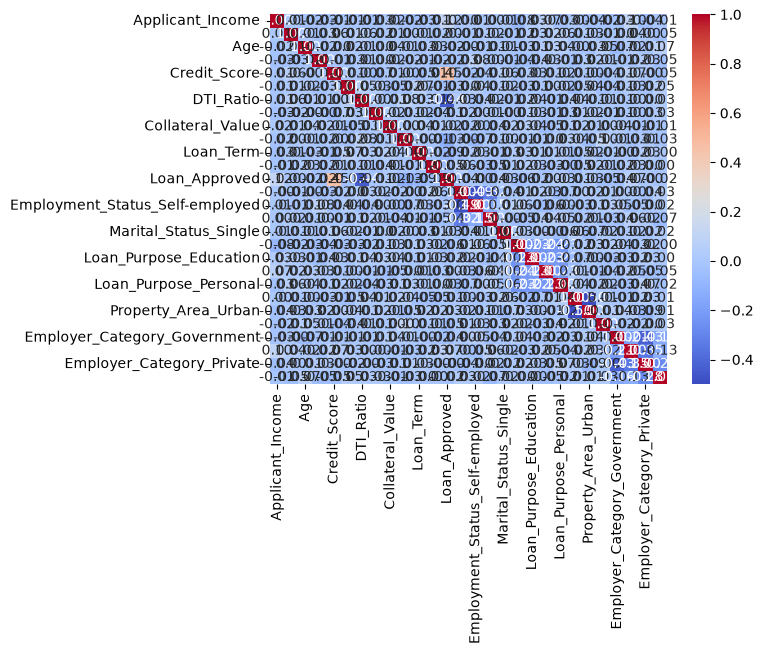

In [14]:
# Corelation Heatmap 
# visual relation of var 
# to check how relationship is strong beetween datasets 
# it returns 
# 1: perfect corelation if x1 inc x2 incn 
# -1: perfect negative corelatoin if x1 inc then x2 dec that is negative ceorelation 
# 0 no corelatino 

nums_col=data.select_dtypes("number")

corr_matrix=nums_col.corr()

sns.heatmap(corr_matrix,annot=True,fmt=".2f",cmap="coolwarm")

In [15]:
X=data.drop("Loan_Approved",axis=1)
Y=data["Loan_Approved"]

data.dtypes

Applicant_Income                   float64
Coapplicant_Income                 float64
Age                                float64
Dependents                         float64
Credit_Score                       float64
Existing_Loans                     float64
DTI_Ratio                          float64
Savings                            float64
Collateral_Value                   float64
Loan_Amount                        float64
Loan_Term                          float64
Education_Level                      int64
Loan_Approved                        int64
Employment_Status_Salaried         float64
Employment_Status_Self-employed    float64
Employment_Status_Unemployed       float64
Marital_Status_Single              float64
Loan_Purpose_Car                   float64
Loan_Purpose_Education             float64
Loan_Purpose_Home                  float64
Loan_Purpose_Personal              float64
Property_Area_Semiurban            float64
Property_Area_Urban                float64
Gender_Male

In [16]:
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.2,random_state=42)
scalar = StandardScaler()

X_train_scaled=scalar.fit_transform(X_train)
X_test_scaled=scalar.transform(X_test)

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score,accuracy_score,recall_score

log_model=LogisticRegression()
log_model.fit(X_train_scaled,Y_train)
y_pred=log_model.predict(X_test_scaled)
print(accuracy_score(Y_test,y_pred))
print(recall_score(Y_test,y_pred))
print(precision_score(Y_test,y_pred))


0.865
0.7704918032786885
0.7833333333333333


In [18]:
from sklearn.neighbors import KNeighborsClassifier
knn=KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled,Y_train)
y_pred=knn.predict(X_test_scaled)
print(accuracy_score(Y_test,y_pred))
print(recall_score(Y_test,y_pred))
print(precision_score(Y_test,y_pred))



0.76
0.5245901639344263
0.6274509803921569


In [19]:
from sklearn.naive_bayes import GaussianNB
gb=GaussianNB()
gb.fit(X_train_scaled,Y_train)
y_pred=gb.predict(X_test_scaled)
print(accuracy_score(Y_test,y_pred))
print(recall_score(Y_test,y_pred))
print(precision_score(Y_test,y_pred))



0.865
0.7377049180327869
0.8035714285714286


In [20]:
# Feature Enginnering 

data["DTI_Ratio"]=data["DTI_Ratio"]**2
data["Credit_Score"]=data["Credit_Score"]**2

X=data.drop(columns=["DTI_Ratio","Credit_Score"])
Y=data["Loan_Approved"]

X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.2,random_state=42)
scalar = StandardScaler()

X_train_scaled=scalar.fit_transform(X_train)
X_test_scaled=scalar.transform(X_test)


# After feature Enginnering 

log_model=LogisticRegression()
log_model.fit(X_train_scaled,Y_train)
y_pred=log_model.predict(X_test_scaled)
print(accuracy_score(Y_test,y_pred))
print(recall_score(Y_test,y_pred))
print(precision_score(Y_test,y_pred))


1.0
1.0
1.0


In [21]:
from sklearn.neighbors import KNeighborsClassifier
knn=KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled,Y_train)
y_pred=knn.predict(X_test_scaled)
print(accuracy_score(Y_test,y_pred))
print(recall_score(Y_test,y_pred))
print(precision_score(Y_test,y_pred))



0.91
0.7213114754098361
0.9777777777777777
